# Blockpose detector — current synthetic milestone

This is the reproducible **seed 0** status of the geometry-only detector. Green boxes are
detections. Dashed orange boxes and all matching/error numbers are **evaluation-only labels**;
the detector never receives synthetic instance IDs, poses, or locations.

Current milestone: cutoff-aware evaluation, richer raycast degradations, local ground-plane
height, known-dimension top+side center recovery, and stratified diagnostics. Real-data TFs are
intentionally deferred until the synchronized export arrives.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def find_repo_root():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / ".."]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "pyproject.toml").is_file() and (candidate / "python/blockpose").is_dir():
            return candidate
    raise RuntimeError("Could not locate repository root from notebook working directory")


REPO_ROOT = find_repo_root()
for path in (REPO_ROOT / "python", REPO_ROOT / "tools"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from blockpose.detection import DetectionParams, detect_scene_sample
from blockpose.evaluate import evaluate
from blockpose.scenario_matrix import generate_scenario_matrix
from blockpose.synth import BLOCK_DIMS
import eval_detector

SEED = 0
CASES = {case.name: sample for case, sample in generate_scenario_matrix(SEED)}

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
def box_edges(pose, dims=BLOCK_DIMS):
    half = np.asarray(dims) / 2
    corners = np.array([[x, y, z] for x in (-half[0], half[0])
                        for y in (-half[1], half[1]) for z in (-half[2], half[2])])
    corners = (pose.rotation @ corners.T).T + pose.position
    edges = [(i, j) for i in range(8) for j in range(i + 1, 8)
             if np.count_nonzero(np.array([(i >> k) & 1 for k in range(3)]) !=
                                 np.array([(j >> k) & 1 for k in range(3)])) == 1]
    return [(corners[i], corners[j]) for i, j in edges]


def set_equal_3d(ax, arrays, padding=0.06, min_span=0.5):
    finite = [np.asarray(a, float).reshape(-1, 3) for a in arrays if np.asarray(a).size]
    points = np.vstack(finite) if finite else np.zeros((1, 3))
    points = points[np.all(np.isfinite(points), axis=1)]
    if not len(points):
        points = np.zeros((1, 3))
    low, high = points.min(axis=0), points.max(axis=0)
    spans = np.maximum(high - low, min_span)
    spans *= 1.0 + 2.0 * padding
    center = (low + high) / 2.0
    ax.set_xlim(center[0] - spans[0] / 2, center[0] + spans[0] / 2)
    ax.set_ylim(center[1] - spans[1] / 2, center[1] + spans[1] / 2)
    ax.set_zlim(center[2] - spans[2] / 2, center[2] + spans[2] / 2)
    ax.set_box_aspect(spans)


def overlay(name, title):
    sample = CASES[name]
    detections = detect_scene_sample(sample, DetectionParams())
    result = evaluate(detections, sample.ground_truth)
    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection="3d")
    stride = max(len(sample.points) // 10000, 1)
    shown = sample.points[::stride]
    plotted = [shown]
    ax.scatter(shown[:, 0], shown[:, 1], shown[:, 2], s=0.35, c="0.55", alpha=0.35)
    for pose in sample.ground_truth:
        for a, b in box_edges(pose):
            ax.plot(*zip(a, b), color="tab:orange", linestyle="--", linewidth=1.2)
            plotted.append(np.vstack([a, b]))
    for pose in detections:
        for a, b in box_edges(pose):
            ax.plot(*zip(a, b), color="tab:green", linewidth=1.8)
            plotted.append(np.vstack([a, b]))
    set_equal_3d(ax, plotted)
    ax.set(title=title, xlabel="world X [m]", ylabel="world Y [m]", zlabel="world Z [m]")
    ax.view_init(elev=24, azim=-58)
    print({"matched": result.matched, "FP": result.unmatched_det, "FN": result.unmatched_gt,
           "translation_p95_m": result.translation_p95_m,
           "rotation_p95_deg": result.rotation_p95_deg})
    plt.show()
    return detections, result

## Success case

The dashed orange cuboid below is an **evaluation-only label**. At seed 0 the isolated tilted
case is recovered with centimeter-scale center error; it is representative of the current
well-observed top-plus-side operating regime.

{'matched': 1, 'FP': 0, 'FN': 0, 'translation_p95_m': 0.004677482453610919, 'rotation_p95_deg': 0.060213201556681625}


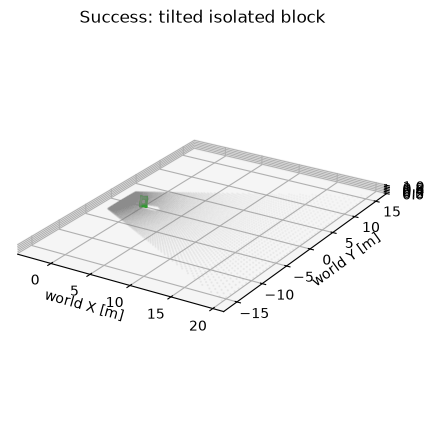

In [3]:
success_det, success_eval = overlay('isolated_tilt_7deg', 'Success: tilted isolated block')

## Compact gate and stratified baseline

Only the original isolated suite is gated. The scenario matrix is deliberately diagnostic:
weak families remain visible instead of being averaged into the success number.

In [4]:
metrics = eval_detector.run_suite(seed=SEED)
print("GATE", {key: metrics[key] for key in
      ("recall", "precision", "translation_p95_m", "rotation_p95_deg",
       "false_positives_empty")})
print("\nSTRATIFIED DIAGNOSTICS")
for family, values in metrics["diagnostics_stratified"].items():
    print(f"{family:16s} recall={values['recall']:.2f} precision={values['precision']:.2f} "
          f"FP={values['false_positives']} t_p95={values['translation_p95_m']}")

GATE {'recall': 1.0, 'precision': 1.0, 'translation_p95_m': 0.01655687275415733, 'rotation_p95_deg': 0.38597283762210677, 'false_positives_empty': 0}

STRATIFIED DIAGNOSTICS
isolated_range   recall=1.00 precision=1.00 FP=0 t_p95=0.052502261545774025
tilt             recall=1.00 precision=1.00 FP=0 t_p95=0.0029644137140613963
noise            recall=1.00 precision=1.00 FP=0 t_p95=0.018473419487214454
dropout          recall=1.00 precision=1.00 FP=0 t_p95=0.0009051505935499796
multi_block      recall=1.00 precision=1.00 FP=0 t_p95=0.01905536022232418
touching         recall=0.00 precision=0.00 FP=0 t_p95=None
stack            recall=0.83 precision=1.00 FP=0 t_p95=0.011319995986358277
clutter          recall=1.00 precision=1.00 FP=0 t_p95=0.009917720066222518
hard_negative    recall=0.00 precision=0.00 FP=0 t_p95=None


## Hard-negative improvement and honest named failures

**Touching row:** the seamless row has no measured internal interface and is geometrically
equivalent to one elongated cuboid. The detector conservatively emits no blocks instead of
inventing three from outer extent alone.

**Hard-negative-only:** ground-relative known-height evidence rejects these shorter boxes.

**Two-block stack:** only the observable top block is recovered. The buried interface supplies no
surface evidence, so the lower pose must not be invented from the synthetic layout.

**Far range:** optional sensor context now scales geometric support thresholds by expected
range-dependent angular density, recovering this sparse case without location-specific tuning.

{'matched': 0, 'FP': 0, 'FN': 3, 'translation_p95_m': None, 'rotation_p95_deg': None}


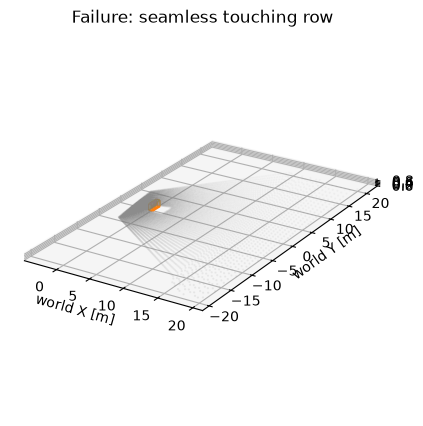

{'matched': 0, 'FP': 0, 'FN': 0, 'translation_p95_m': None, 'rotation_p95_deg': None}


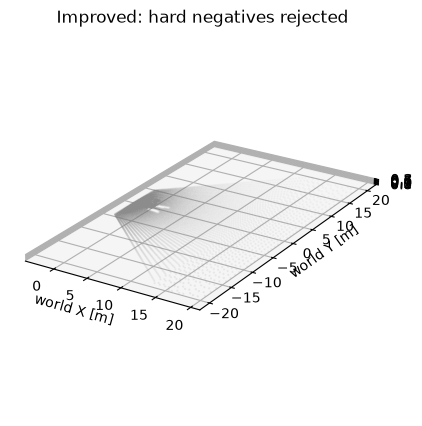

{'matched': 1, 'FP': 0, 'FN': 1, 'translation_p95_m': 0.0013129055186727578, 'rotation_p95_deg': 0.8288067959287251}


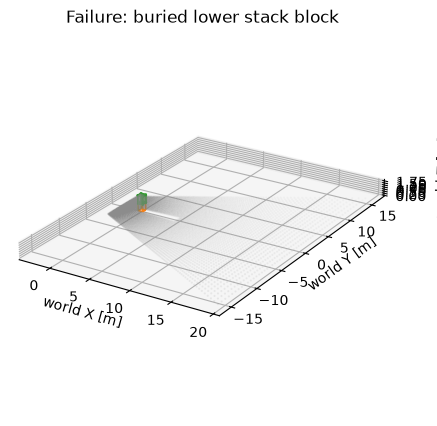

{'matched': 1, 'FP': 0, 'FN': 0, 'translation_p95_m': 0.02831413565866152, 'rotation_p95_deg': 0.6921129674106884}


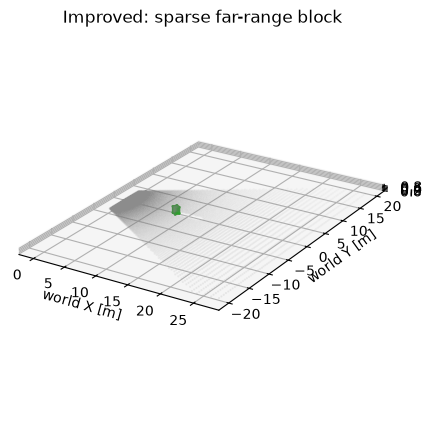

In [5]:
touching_det, touching_eval = overlay("touching_row", "Failure: seamless touching row")
negative_det, negative_eval = overlay("hard_negative_only", "Improved: hard negatives rejected")
stack_det, stack_eval = overlay("two_stack", "Failure: buried lower stack block")
far_det, far_eval = overlay("isolated_far", "Improved: sparse far-range block")

## Next detector architecture

```text
validated cloud + sensor origin
  → local ground frame + permissive connected regions
  → PlanePatch extraction (normal, equation, residual, hull, coverage)
  → multiple known-size CuboidHypothesis proposals per region
  → deterministic HypothesisEvidence
       surface support + face coverage + dimension consistency
       expected-visible missing faces + free-space violations + overlap
  → robust box refinement
  → score-ordered selection / explained-point discounting
  → pose + observability + calibrated confidence + diagnostics
```

The next acceptance targets are richer face coverage and calibrated evidence. Stacked blocks
with buried interfaces must be reported as unobservable unless visible geometry supplies enough
evidence; layout priors must not masquerade as measurements.